In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"D:\Data Analystic\Machine learning\bank.csv")
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [3]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [4]:
df.describe(include='object')

C:\Users\hp\AppData\Local\Temp\ipykernel_20444\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,11162,11162,11162,11162,11162,11162,11162,11162,11162,11162
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2566,6351,5476,10994,5881,9702,8042,2824,8326,5873


In [5]:
df.isnull().sum()
(df.isnull().sum()/len(df))*100

age          0.0
job          0.0
marital      0.0
education    0.0
default      0.0
balance      0.0
housing      0.0
loan         0.0
contact      0.0
day          0.0
month        0.0
duration     0.0
campaign     0.0
pdays        0.0
previous     0.0
poutcome     0.0
deposit      0.0
dtype: float64

In [6]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [7]:
print(df['deposit'].value_counts())
print(df['deposit'].value_counts(normalize=True)*100)

deposit
no     5873
yes    5289
Name: count, dtype: int64
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


In [8]:
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = df.select_dtypes(include=['object']).columns.tolist()
print("Numeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numeric Features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


C:\Users\hp\AppData\Local\Temp\ipykernel_20444\1709423883.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns.tolist()


Text(0, 0.5, 'Number of Customer')

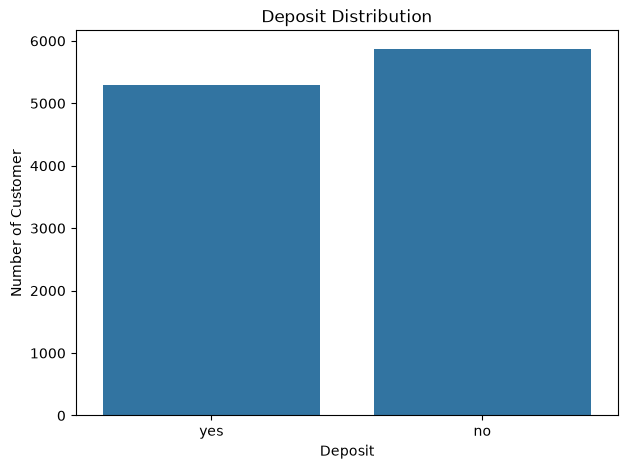

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))
sns.countplot(data=df,x='deposit')
plt.title('Deposit Distribution')
plt.xlabel('Deposit')
plt.ylabel('Number of Customer')

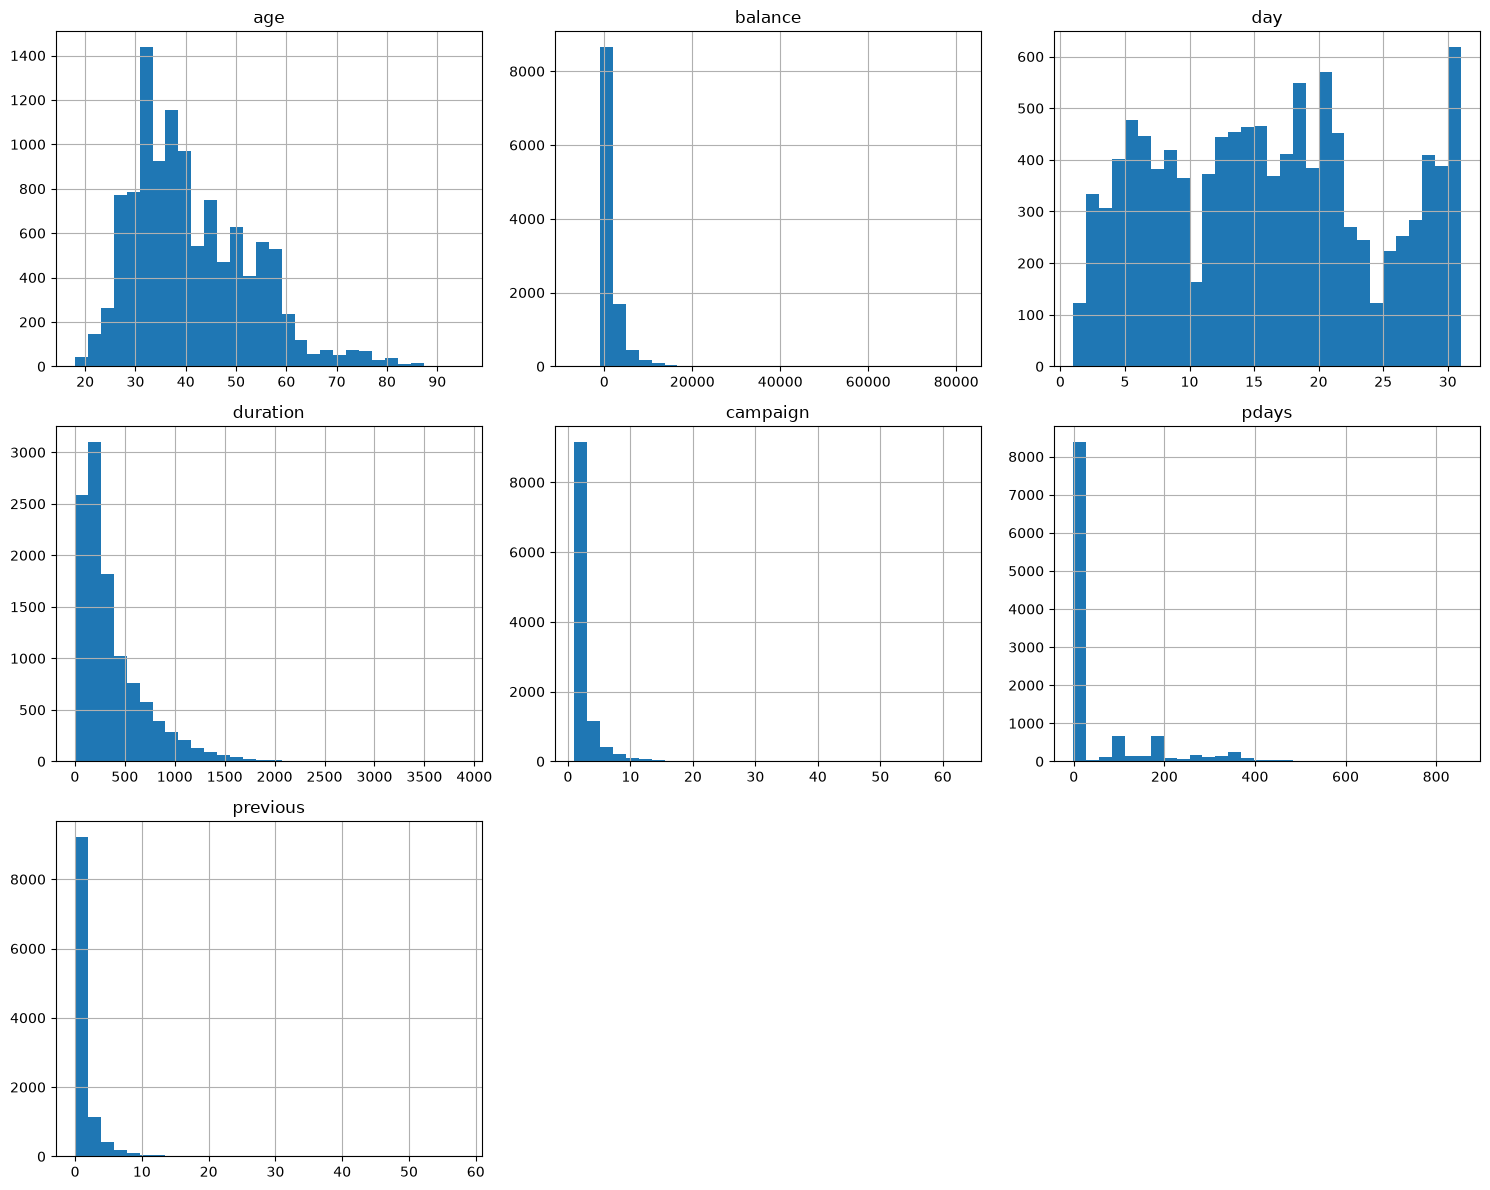

In [10]:
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_features].hist(figsize=(15,12),bins=30)
plt.tight_layout()
plt.show()

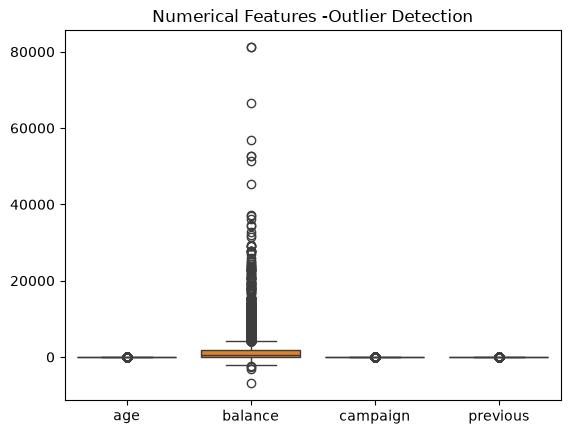

In [11]:
plt.Figure(figsize=(12,6))
sns.boxplot(data=df[['age','balance','campaign','previous']])
plt.title('Numerical Features -Outlier Detection')
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_20444\2098932231.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include='object').columns


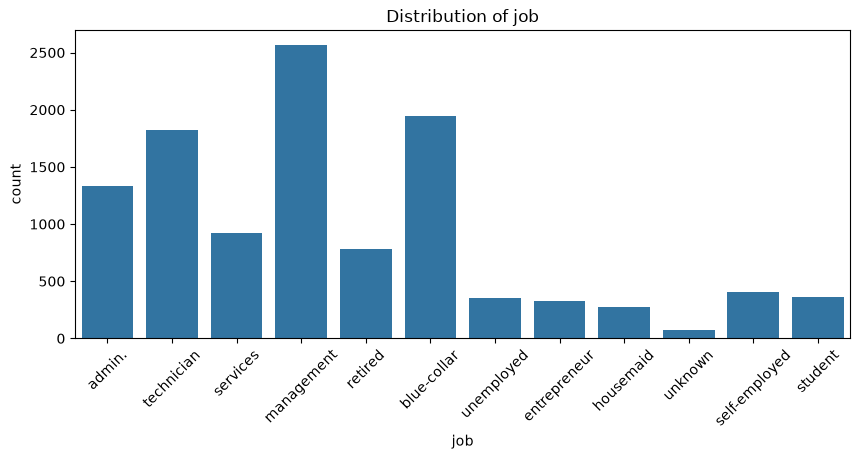

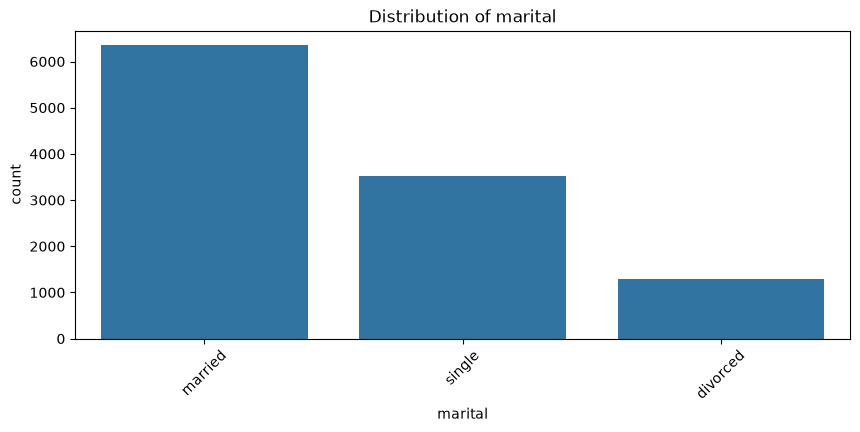

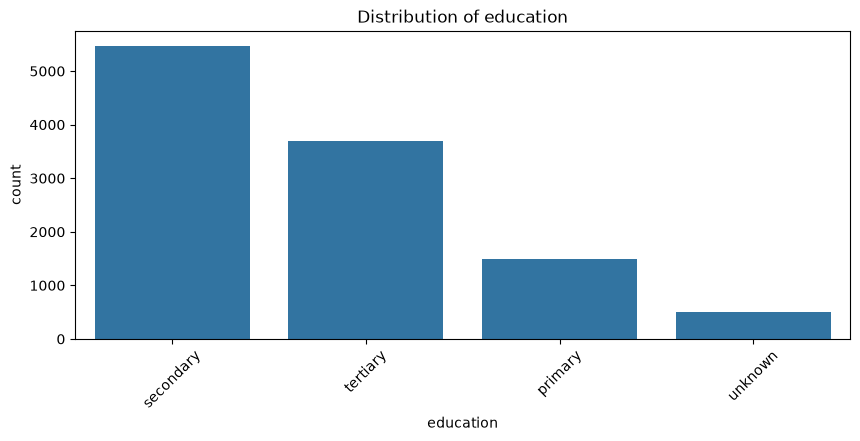

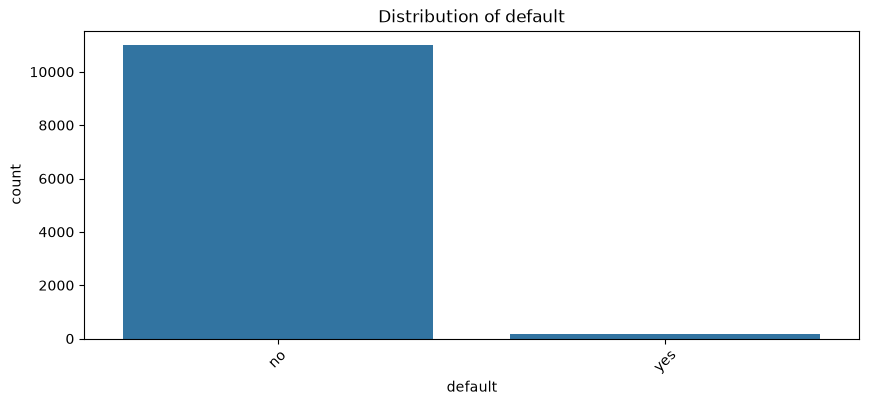

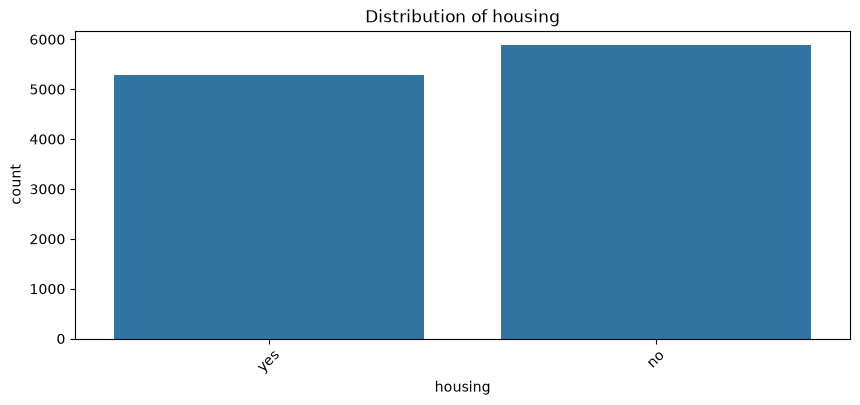

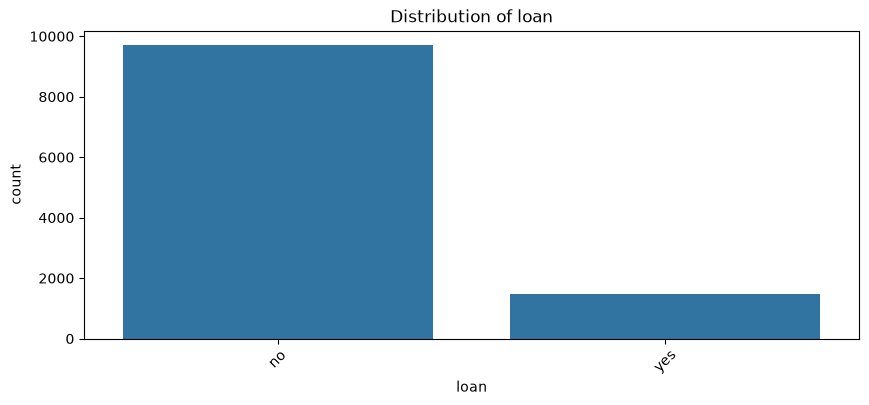

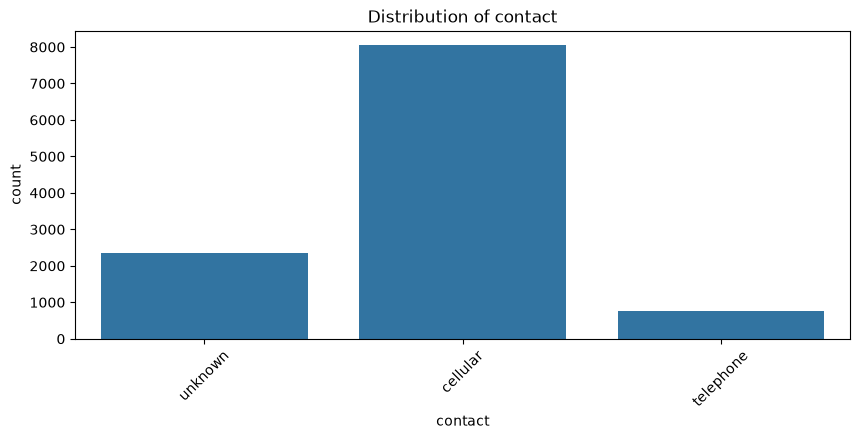

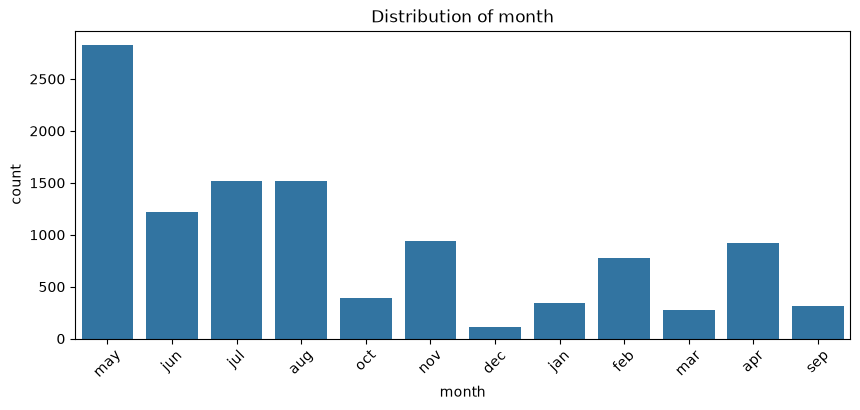

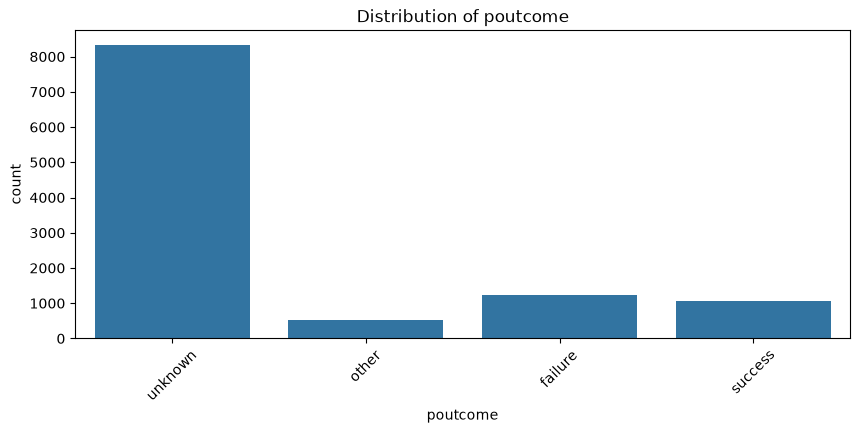

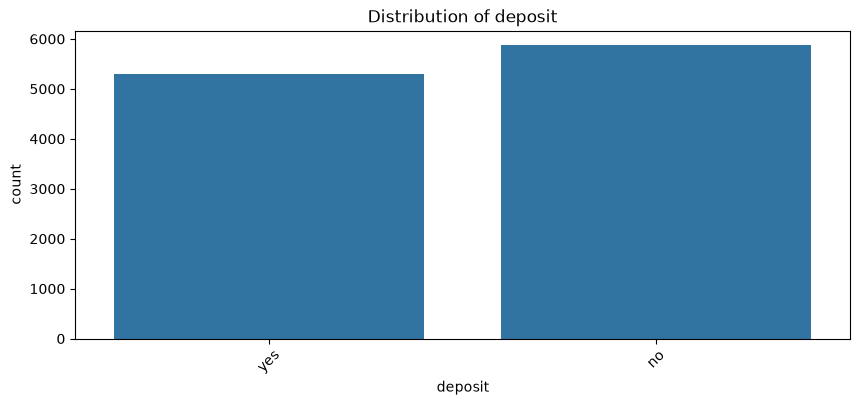

In [12]:
categorical_features = df.select_dtypes(include='object').columns

for col in categorical_features:
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.countplot(data=df, x=col, ax=ax)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.show()
    plt.close(fig)

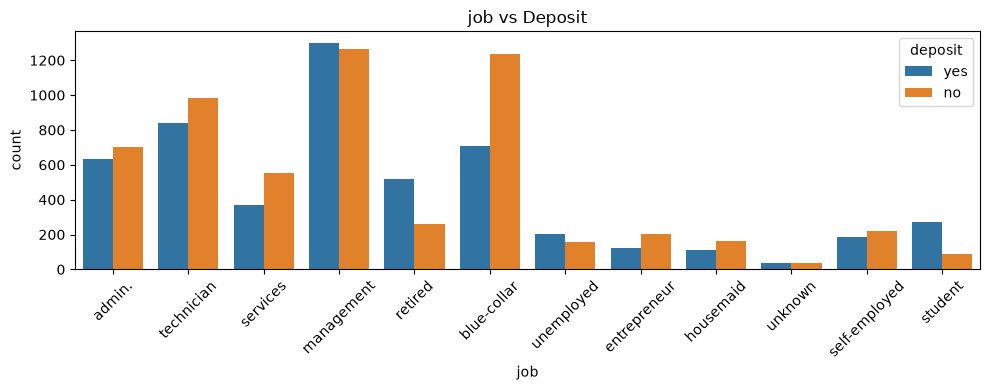

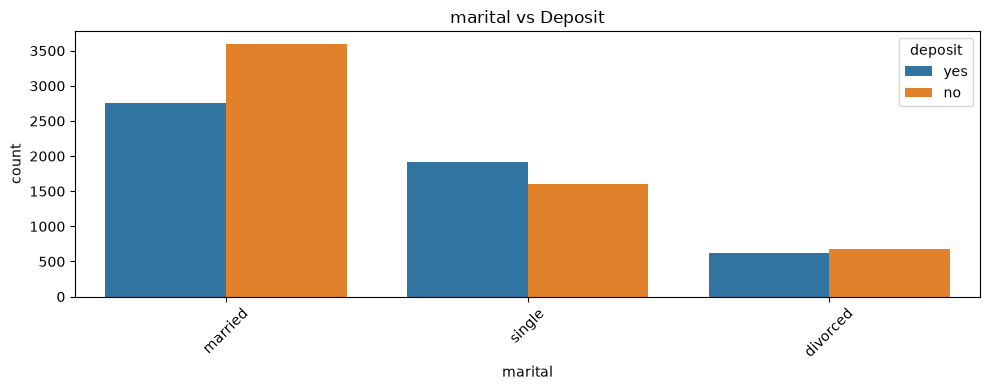

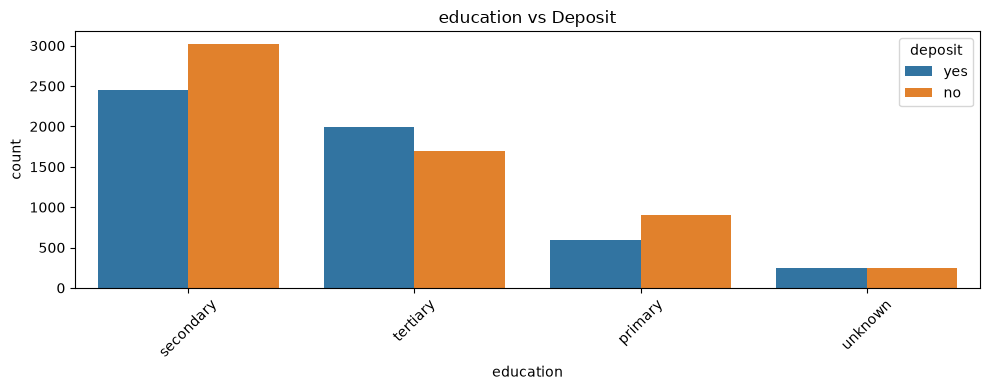

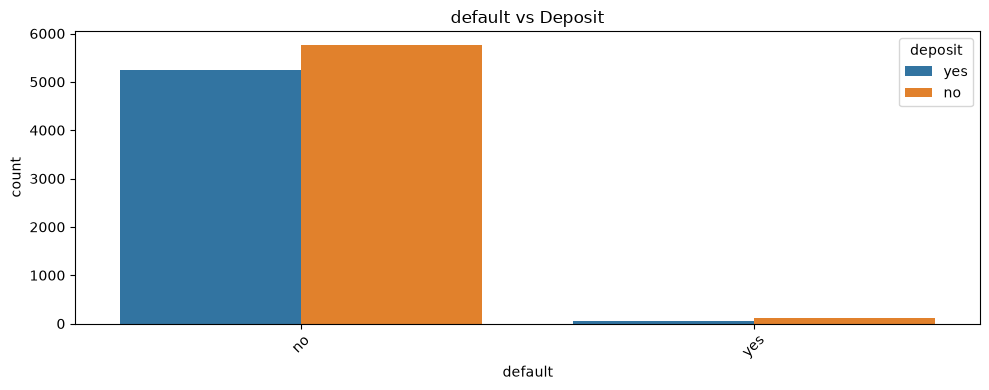

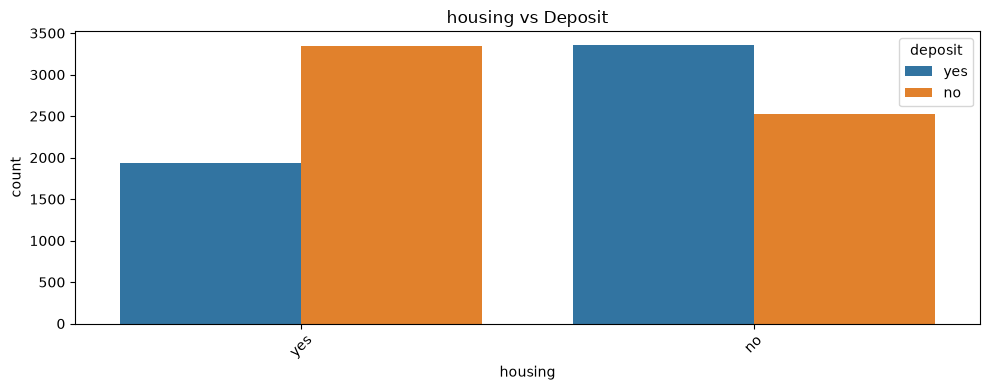

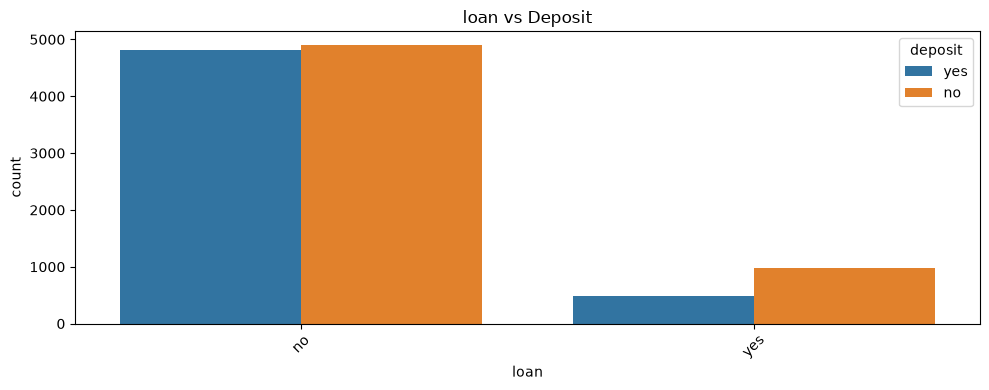

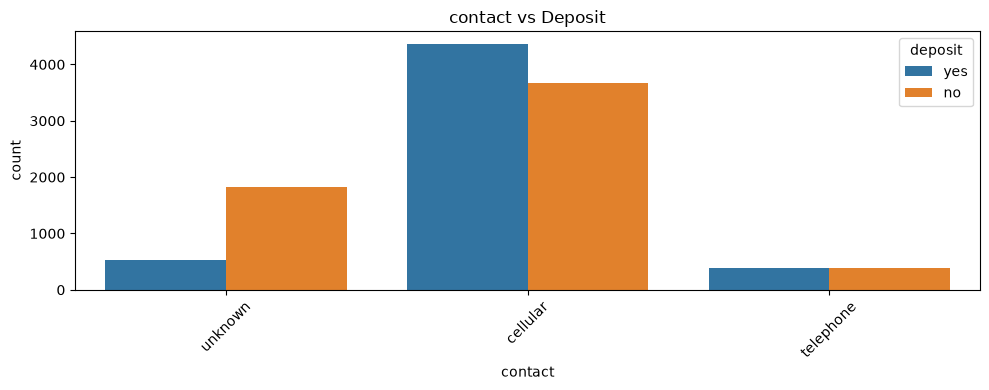

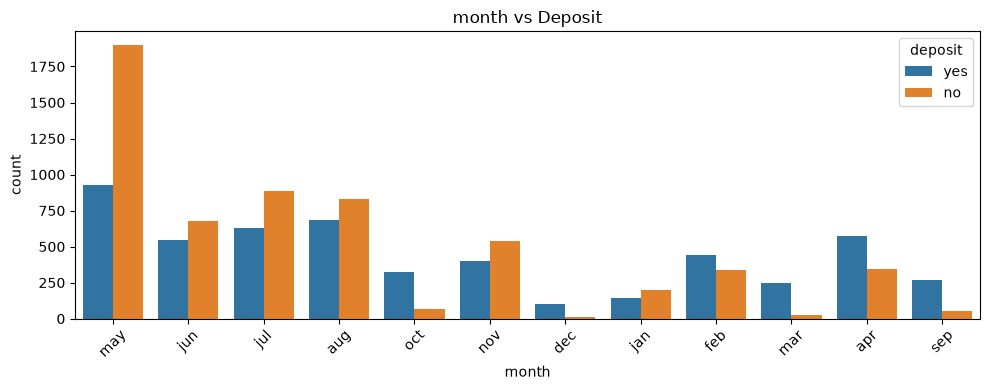

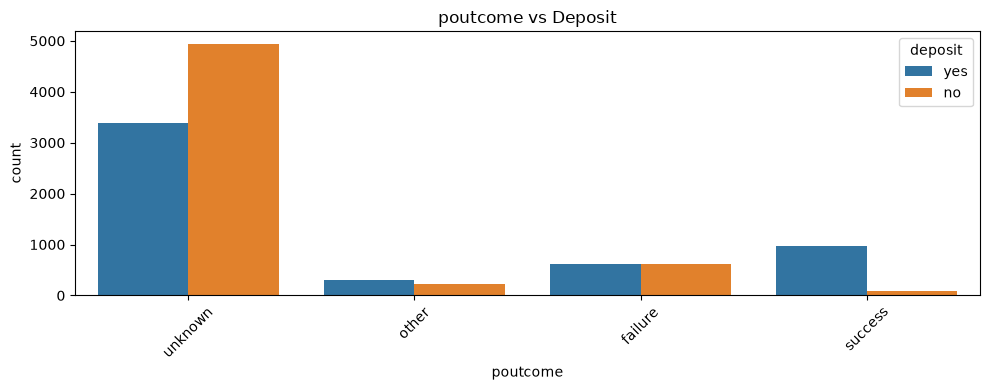

In [13]:
categorical_predictors= [col for col in categorical_features if col != 'deposit']

for col in categorical_predictors:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col, hue='deposit')
    plt.title(f'{col} vs Deposit')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [14]:
pd.crosstab(df['job'], df['deposit'], normalize='index') * 100

deposit,no,yes
job,,
admin.,52.698651,47.301349
blue-collar,63.580247,36.419753
entrepreneur,62.500000,37.500000
housemaid,60.218978,39.781022
management,49.298519,50.701481
retired,33.676093,66.323907
self-employed,53.827160,46.172840
services,60.021668,39.978332
student,25.277778,74.722222


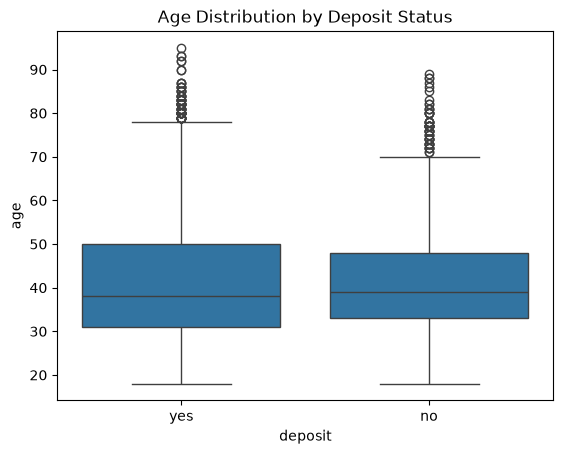

In [15]:
plt.Figure(figsize=(8,5))
sns.boxplot(data=df, x='deposit', y='age')
plt.title('Age Distribution by Deposit Status')
plt.show()

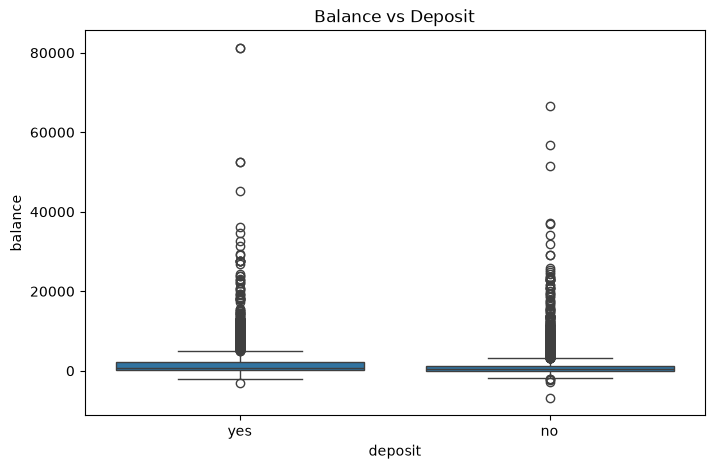

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='deposit', y='balance')
plt.title('Balance vs Deposit')
plt.show()

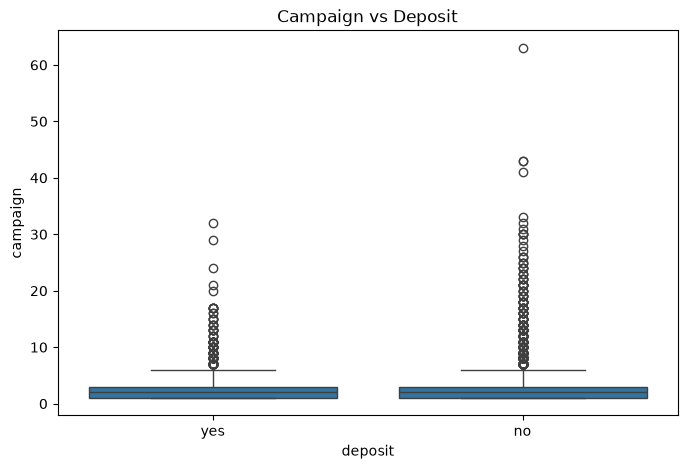

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='deposit', y='campaign')
plt.title('Campaign vs Deposit')
plt.show()

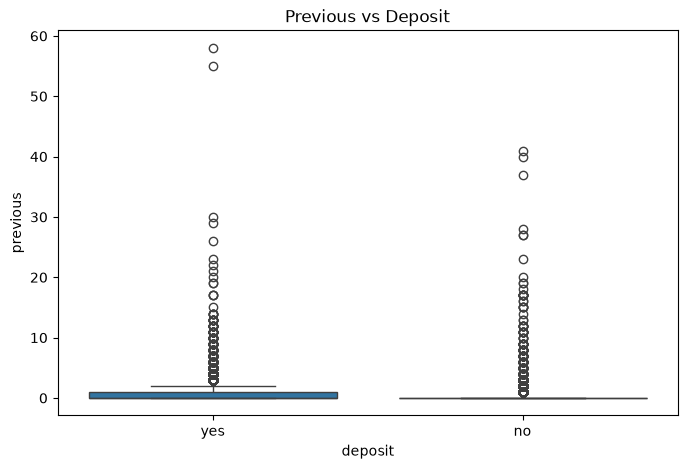

In [18]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='deposit', y='previous')
plt.title('Previous vs Deposit')
plt.show()

In [19]:
x = df.drop(columns=['deposit','duration'])
y = df['deposit']

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)
print("X_train: ", X_train.shape)
print("y_train: ", y_train.shape)
print("\nTraining target distribution:\n", y_train.value_counts(normalize=True)*100)
print("\nTesting target distribution:\n", y_test.value_counts(normalize=True)*100)

X_train:  (8929, 15)
y_train:  (8929,)

Training target distribution:
 deposit
no     52.615074
yes    47.384926
Name: proportion, dtype: float64

Testing target distribution:
 deposit
no     52.619794
yes    47.380206
Name: proportion, dtype: float64


The target distribution is almost identical across the training and testing sets, confirming that stratified splitting preserved the class proportions.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [22]:
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()
print("Numeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numeric Features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


C:\Users\hp\AppData\Local\Temp\ipykernel_20444\3653882990.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()


In [23]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [24]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print("X_train_preprocessed :", X_train_preprocessed.shape)
print("X_test_preprocessed :", X_test_preprocessed.shape)

X_train_preprocessed : (8929, 50)
X_test_preprocessed : (2233, 50)


In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train_preprocessed, y_train)
y_pred_baseline = baseline_model.predict(X_test_preprocessed)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
print("Baseline Model Accuracy:", baseline_accuracy)

Baseline Model Accuracy: 0.5261979399910435


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train_preprocessed, y_train)
y_pred_logistic = logistic_model.predict(X_test_preprocessed)
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
print("Logistic Regression Accuracy:", logistic_accuracy)
print("Classification Report:")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.6954769368562472
Classification Report:
              precision    recall  f1-score   support

          no       0.67      0.82      0.74      1175
         yes       0.73      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.70      0.69      2233



In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_preprocessed, y_train)
y_pred_tree = tree_model.predict(X_test_preprocessed)
tree_accuracy = accuracy_score(y_test, y_pred_tree)
print("Decision Tree Accuracy:", tree_accuracy)
print("Classification Report:")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.6363636363636364
Classification Report:
              precision    recall  f1-score   support

          no       0.65      0.67      0.66      1175
         yes       0.62      0.60      0.61      1058

    accuracy                           0.64      2233
   macro avg       0.64      0.63      0.63      2233
weighted avg       0.64      0.64      0.64      2233



In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_preprocessed, y_train)
y_pred_rf = rf_model.predict(X_test_preprocessed)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", rf_accuracy)
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.7232422749664129
Classification Report:
              precision    recall  f1-score   support

          no       0.71      0.81      0.75      1175
         yes       0.75      0.63      0.68      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.72      0.72      2233



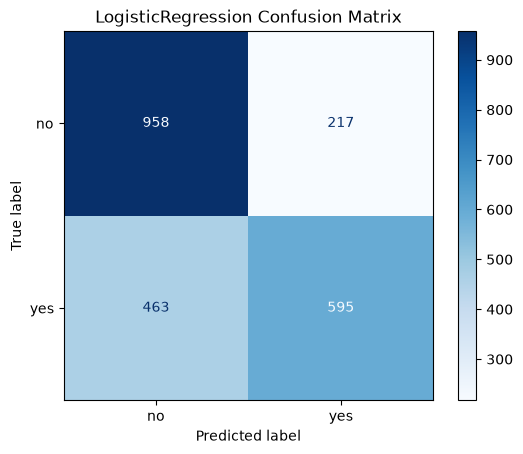

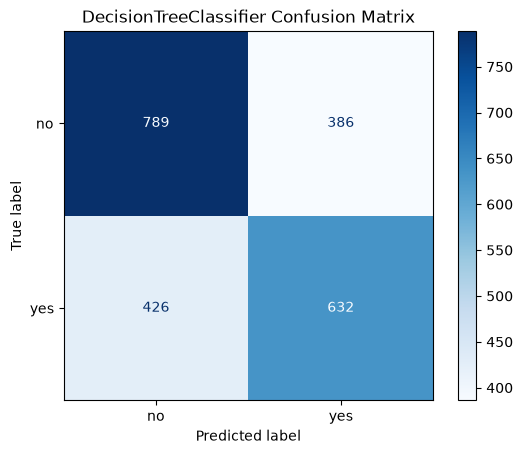

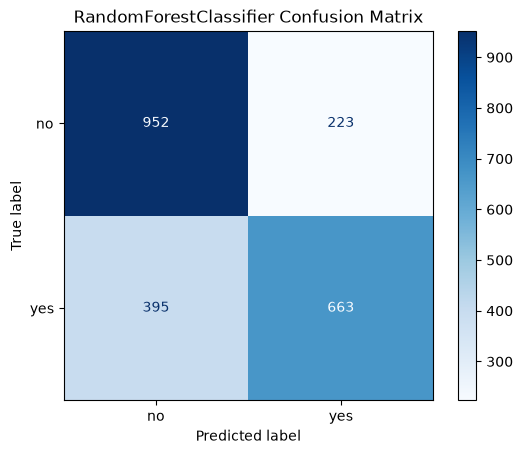

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {'LogisticRegression': (logistic_model, y_pred_logistic),
          'DecisionTreeClassifier': (tree_model, y_pred_tree),
          'RandomForestClassifier': (rf_model, y_pred_rf)}
for name, prediction in models.items():
    cm = confusion_matrix(y_test, prediction[1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=prediction[0].classes_)
    disp.plot(cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.show()

Model Selection Conclusion:
Random Forest was selected as the current best candidate because it achieved the highest accuracy (72%) and detected the largest number of actual subscribers (663), while producing the lowest number of false negatives (395).
However, Logistic Regression performed slightly better in identifying non-subscribers.

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'recall_yes': make_scorer(recall_score, pos_label='yes'),
    'precision_yes': make_scorer(precision_score, pos_label='yes'),
    'f1_yes': make_scorer(f1_score, pos_label='yes')
}

cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric, scores in cv_results.items():
    if metric.startswith('test_'):
        print(f'{metric}: {scores.mean():.3f} (+/- {scores.std():.3f})')

test_accuracy: 0.724 (+/- 0.002)
test_recall_yes: 0.645 (+/- 0.018)
test_precision_yes: 0.740 (+/- 0.011)
test_f1_yes: 0.689 (+/- 0.006)


Random Forest maintains relatively consistent performance across cross-validation folds and test evaluation, indicating good performance stability and making it a promising candidate for predicting potential bank customers.

In [31]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.5]
}

scoring = {
    'recall_yes': make_scorer(recall_score, pos_label='yes'),
    'precision_yes': make_scorer(precision_score, pos_label='yes'),
    'f1_yes': make_scorer(f1_score, pos_label='yes'),
    'accuracy': 'accuracy'
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring=scoring,
    refit='recall_yes',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 0.5], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'accuracy': 'accuracy', 'f1_yes': make_scorer(f...pos_label=yes), 'precision_yes': make_scorer(p...pos_label=yes), 'recall_yes': make_scorer(r...pos_label=yes)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall_yes'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`

In [32]:
print("Best Parameters:")
print(random_search.best_params_)

best_idx = random_search.best_index_

print("\nBest Model Performance:")

for metric in [
    'mean_test_recall_yes',
    'mean_test_precision_yes',
    'mean_test_f1_yes',
    'mean_test_accuracy'
]:
    print(f"{metric}: {random_search.cv_results_[metric][best_idx]:.3f}")

Best Parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}

Best Model Performance:
mean_test_recall_yes: 0.649
mean_test_precision_yes: 0.745
mean_test_f1_yes: 0.693
mean_test_accuracy: 0.728


Hyperparameter tuning slightly improved the Random Forest model's performance across all evaluation metrics. Recall, precision, F1-score, and accuracy showed small improvements, indicating that the optimized parameters provide better overall performance than the default settings.

In [33]:
best_rf_model = random_search.best_estimator_

y_pred_best_rf = best_rf_model.predict(X_test)

from sklearn.metrics import classification_report, accuracy_score

print("Final Test Accuracy:", accuracy_score(y_test, y_pred_best_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_rf))

Final Test Accuracy: 0.7245857590685177

Classification Report:
              precision    recall  f1-score   support

          no       0.71      0.81      0.76      1175
         yes       0.75      0.63      0.69      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.72      0.72      2233



In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_best_rf,
    labels=['no', 'yes']
)

print(cm)

[[949 226]
 [389 669]]


The confusion matrix shows that the Random Forest model correctly identified 669 potential subscribers and 949 non-subscribers. However, it produced 226 false positives and 389 false negatives. False negatives represent missed business opportunities, while false positives may lead to unnecessary marketing efforts. Therefore, improving the recall for potential subscribers could help the bank identify more interested customers.

1. Business Insights

Based on the Exploratory Data Analysis (EDA) and Model Evaluation, several important business insights can be identified:

Insight 1 – Customer Targeting

Students had the highest subscription rate among all job categories (approximately 74.72%).

Business Recommendation: The bank should consider targeting students through focused marketing campaigns to increase subscription rates.

Insight 2 – Blue-collar Customers

Blue-collar customers had the highest non-subscription rate (approximately 63.55%).

Business Recommendation: The bank should review its marketing strategy for this segment instead of allocating the same marketing effort to every customer group.

Insight 3 – Model Performance

The Random Forest model achieved 72.45% accuracy and 63% recall for subscribers.

Business Recommendation: The model can help the bank prioritize potential subscribers, but further improvements are needed before relying on it for large-scale marketing campaigns.

Insight 4 – Missed Opportunities

The model produced 389 False Negatives, meaning it failed to identify 389 customers who actually subscribed.

Business Recommendation: Improving Recall for the "Yes" class could help the bank reduce missed subscription opportunities and identify more potential customers.

In [35]:
import joblib

best_rf_model = random_search.best_estimator_

joblib.dump(best_rf_model, 'bank_deposit_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [36]:
import os
import joblib

# Get the best trained model
best_rf_model = random_search.best_estimator_

# Set project folder
project_path = os.path.join(
    os.getcwd(),
    'Bank Term Deposit Prediction'
)

os.makedirs(project_path, exist_ok=True)

# Save the model
model_path = os.path.join(
    project_path,
    'bank_deposit_model.pkl'
)

joblib.dump(best_rf_model, model_path)

print("Model saved successfully!")
print("File exists:", os.path.exists(model_path))
print("Saved at:", model_path)

Model saved successfully!
File exists: True
Saved at: d:\Data Analystic\Machine learning\Bank Term Deposit Prediction\bank_deposit_model.pkl
